# Matematyczne podstawy uczenia maszynowego

Uczenie maszynowe stoi na kilku prostych ideach matematycznych. **Nie będziemy niczego dowodzić** – pokażemy intuicję i od razu sprawdzimy ją w kodzie. Każde pojęcie wiąże się z konkretnym miejscem w ML, które zobaczysz w kolejnych dniach szkolenia.

**Po tym notatniku będziesz potrafić:**
- opisać dane kilkoma liczbami i wiedzieć, kiedy średnia „kłamie”,
- rozpoznać rozkład normalny i wiedzieć, po co standaryzujemy cechy,
- odróżnić korelację od przyczynowości,
- zapisać dane i model jako wektory i macierze,
- zrozumieć, że **regresja liniowa to jedno mnożenie macierzy**.

| Temat | Do czego przyda się w ML |
|---|---|
| Statystyka opisowa, rozkłady | EDA (Dzień 2), skalowanie cech, wykrywanie wartości odstających |
| Korelacja | wybór cech, interpretacja modeli |
| Prawdopodobieństwo | klasyfikacja, regresja logistyczna (Dzień 3) |
| Wektory i macierze | reprezentacja danych, regresja, sieci neuronowe (Dzień 3 i 5) |
| Odległości | kNN, klasteryzacja, regularyzacja |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)  # powtarzalne losowanie

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


# 1. Statystyka w kontekście ML

## 1.1 Statystyka opisowa: gdzie jest środek i jak duży jest rozrzut

Zacznijmy od przykładu. Wynagrodzenia (w tys. zł) w małej firmie – ostatnia wartość to prezes:

In [2]:
pensje = np.array([4.5, 5.0, 5.2, 5.5, 6.0, 6.2, 6.8, 7.0, 7.5, 45.0])

**Miary środka (tendencji centralnej):**
- **średnia** – suma podzielona przez liczbę wartości; wrażliwa na wartości odstające,
- **mediana** – wartość środkowa po posortowaniu; odporna na wartości odstające,
- **moda** – najczęstsza wartość.

**Miary rozrzutu:**
- **wariancja** – średnia kwadratów odchyleń od średniej,
- **odchylenie standardowe** – pierwiastek z wariancji, w tych samych jednostkach co dane (zwykle: „o ile typowa wartość odbiega od średniej”).

In [3]:
print(f"Średnia           : {pensje.mean():.2f} tys. zł")
print(f"Mediana           : {np.median(pensje):.2f} tys. zł")
print(f"Odchylenie std.   : {pensje.std():.2f} tys. zł")
print(f"Min / max         : {pensje.min()} / {pensje.max()}")

Średnia           : 9.87 tys. zł
Mediana           : 6.10 tys. zł
Odchylenie std.   : 11.74 tys. zł
Min / max         : 4.5 / 45.0


Średnia (9,9 tys.) jest znacznie wyższa niż pensja prawie każdego pracownika – jeden prezes „przeciągnął” ją w górę. **Mediana (6,1 tys.) lepiej opisuje typowego pracownika.**

> **Uwaga na `ddof`.** NumPy domyślnie liczy odchylenie dla *całej populacji* (`ddof=0`), a Pandas – dla *próbki* (`ddof=1`). Dla małych zbiorów wynik się różni.

In [4]:
pensje.std(), pensje.std(ddof=1)

(np.float64(11.744364606056813), np.float64(12.379647275535222))

### Kwartyle i wartości odstające

**Kwartyle** dzielą posortowane dane na cztery równe części. Q1 to 25. percentyl, Q3 – 75. percentyl, a **IQR = Q3 − Q1**. Częsta reguła: wartość jest odstająca, gdy leży dalej niż 1,5 × IQR od Q1 lub Q3. To właśnie pokazuje wykres pudełkowy (*boxplot*).

In [5]:
q1, q3 = np.percentile(pensje, [25, 75])
iqr = q3 - q1
granica = q3 + 1.5 * iqr
print(f"Q1={q1}, Q3={q3}, IQR={iqr}, górna granica={granica}")
pensje[pensje > granica]  # maska logiczna z NumPy

Q1=5.275, Q3=6.95, IQR=1.6749999999999998, górna granica=9.4625


array([45.])

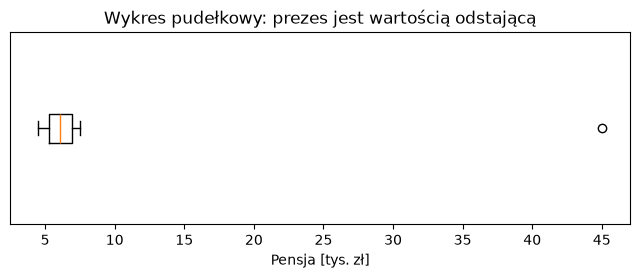

In [6]:
plt.figure(figsize=(8, 2.5))
plt.boxplot(pensje, orientation='horizontal')
plt.title('Wykres pudełkowy: prezes jest wartością odstającą')
plt.xlabel('Pensja [tys. zł]')
plt.yticks([])
plt.show()

**Co z tego wynika dla ML?** Wartości odstające mogą mocno wpłynąć na modele (np. regresję liniową) i na średnie używane przy uzupełnianiu braków. Zawsze warto je zobaczyć *przed* modelowaniem – tym zajmiemy się w EDA na Dniu 2.

## 1.2 Rozkład normalny

**Rozkład** mówi, jak często występują poszczególne wartości. Najważniejszy jest **rozkład normalny** (Gaussa) – krzywa dzwonowa opisana dwoma liczbami: średnią $\mu$ i odchyleniem standardowym $\sigma$. Tak zachowuje się wiele zjawisk (wzrost, błędy pomiarów). Wygenerujmy wzrost 10 000 osób:

**Skąd te dane?** Są *syntetyczne* – generujemy je sami, więc znamy „prawdę” i możemy sprawdzić, czy statystyki ją odtwarzają.
- `rng = np.random.default_rng(42)` to generator liczb pseudolosowych. Liczba 42 to *ziarno* (`seed`): dzięki niemu każdy, kto uruchomi notatnik, dostanie dokładnie te same liczby.
- `rng.normal(loc=170, scale=10, size=10_000)` losuje 10 000 liczb z rozkładu normalnego o średniej `loc` = 170 i odchyleniu standardowym `scale` = 10. Czyli „prawdziwe” parametry to $\mu=170$ i $\sigma=10$, a my zaraz policzymy je z danych (`mu`, `sigma`).

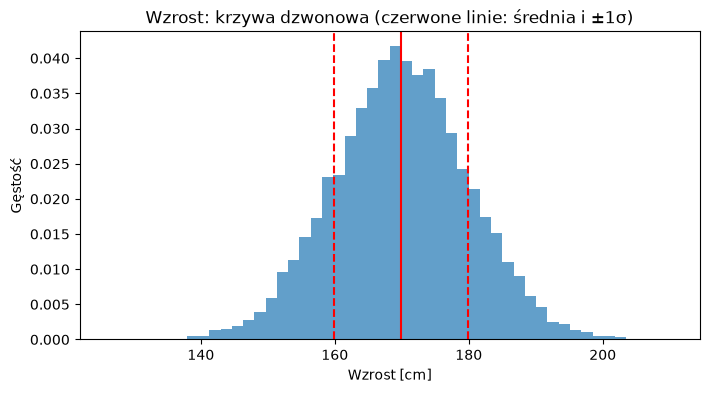

In [7]:
wzrost = rng.normal(loc=170, scale=10, size=10_000)  # średnia 170 cm, odch. std. 10 cm
mu, sigma = wzrost.mean(), wzrost.std()

plt.figure(figsize=(8, 4))
plt.hist(wzrost, bins=50, density=True, alpha=0.7)
for k in (-1, 0, 1):
    plt.axvline(mu + k * sigma, color='red', ls='--' if k else '-')
plt.title('Wzrost: krzywa dzwonowa (czerwone linie: średnia i ±1σ)')
plt.xlabel('Wzrost [cm]')
plt.ylabel('Gęstość')
plt.show()

**Reguła 68–95–99,7** – dla rozkładu normalnego w odległości $k\sigma$ od średniej leży odpowiednio ok. 68%, 95% i 99,7% wartości. Sprawdźmy empirycznie:

In [8]:
for k in (1, 2, 3):
    udzial = np.mean(np.abs(wzrost - mu) < k * sigma)
    print(f"w przedziale ±{k}σ: {udzial:.1%}")

w przedziale ±1σ: 68.2%
w przedziale ±2σ: 95.5%
w przedziale ±3σ: 99.7%


### Nie wszystko jest normalne

Dane o pieniądzach (zarobki, ceny, wartości transakcji) zwykle mają rozkład **skośny** z długim „ogonem” po prawej. Wtedy średnia jest większa niż mediana:

**Skąd te dane?** `rng.lognormal(mean=8.5, sigma=0.6, size=10_000)` losuje liczby, których **logarytm** ma rozkład normalny (parametry `mean` i `sigma` dotyczą logarytmu, a nie samych zarobków). Efekt: wartości zawsze dodatnie, większość stosunkowo niska, a nieliczne bardzo wysokie – tak jak w prawdziwych zarobkach. Typowa wartość (mediana) to ok. $e^{8{,}5}\approx 4900$ zł.

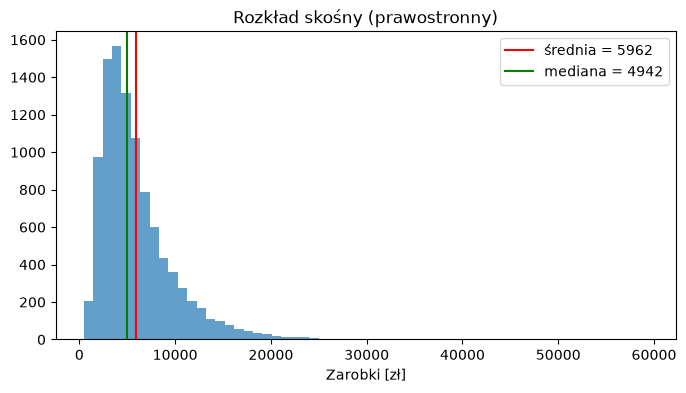

In [9]:
zarobki = rng.lognormal(mean=8.5, sigma=0.6, size=10_000)

plt.figure(figsize=(8, 4))
plt.hist(zarobki, bins=60, alpha=0.7)
plt.axvline(zarobki.mean(), color='red', label=f'średnia = {zarobki.mean():.0f}')
plt.axvline(np.median(zarobki), color='green', label=f'mediana = {np.median(zarobki):.0f}')
plt.title('Rozkład skośny (prawostronny)')
plt.xlabel('Zarobki [zł]')
plt.legend()
plt.show()

### Standaryzacja (z-score)

Wynik standaryzowany mówi, **o ile odchyleń standardowych** wartość leży od średniej:

$$z = \frac{x - \mu}{\sigma}$$

Po standaryzacji cecha ma średnią 0 i odchylenie 1. To podstawowa transformacja przed wieloma modelami ML (w scikit-learn: `StandardScaler`, Dzień 2).

In [10]:
z = (wzrost - mu) / sigma
print(f"średnia z = {z.mean():.3f}, odch. std. z = {z.std():.3f}")
print(f"Osoba o wzroście 190 cm ma z = {(190 - mu) / sigma:.2f}  (ok. 2σ powyżej średniej)")

średnia z = 0.000, odch. std. z = 1.000
Osoba o wzroście 190 cm ma z = 2.00  (ok. 2σ powyżej średniej)


## 1.3 Korelacja

**Współczynnik korelacji Pearsona** $r \in [-1, 1]$ mierzy, jak silnie dwie zmienne zmieniają się razem *w sposób liniowy*: $r\approx 1$ – rosną razem, $r\approx -1$ – jedna rośnie, druga maleje, $r\approx 0$ – brak zależności liniowej.

**Skąd te dane?** Wszystkie trzy zależności budujemy z tej samej zmiennej `x` (200 liczb z rozkładu normalnego o średniej 0 i odchyleniu 1):
- `y_dod = 2 * x + szum` – punkty leżą wokół prostej o nachyleniu 2; `szum` to losowe odchylenia (`rng.normal(scale=1.0, size=200)`), które „rozmywają” prostą,
- `y_brak` – niezależne losowanie, w ogóle nie korzysta z `x`, więc nie ma żadnej zależności,
- `y_kw = x ** 2 + mały szum` – zależność istnieje i jest bardzo silna, ale jest parabolą: dla `x` dodatnich i ujemnych `y` jest podobne, więc „liniowa” korelacja się znosi i wychodzi bliska 0.

`zip(osie, [...], [...])` w pętli po prostu łączy kolejne wykresy z kolejnymi danymi i tytułami.

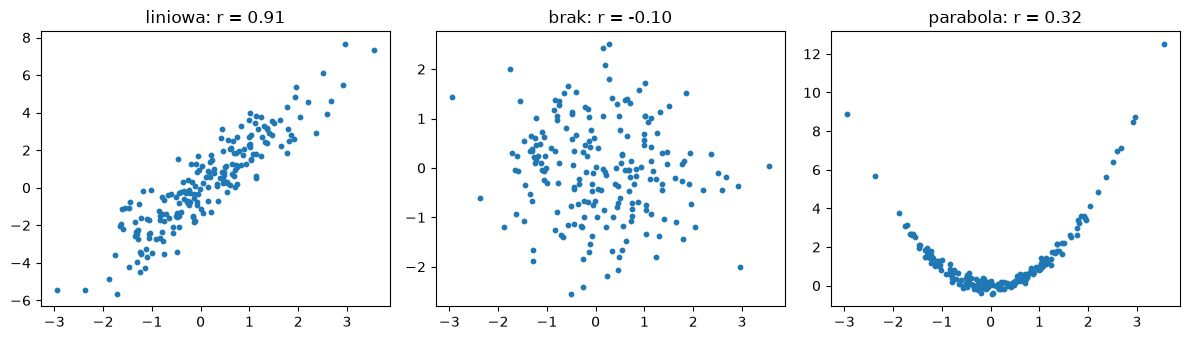

In [11]:
x = rng.normal(size=200)
y_dod = 2 * x + rng.normal(scale=1.0, size=200)   # zależność liniowa
y_brak = rng.normal(size=200)                     # brak zależności
y_kw = x ** 2 + rng.normal(scale=0.2, size=200)   # zależność nieliniowa (parabola)

fig, osie = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, y, tytul in zip(osie, [y_dod, y_brak, y_kw], ['liniowa', 'brak', 'parabola']):
    ax.scatter(x, y, s=10)
    ax.set_title(f"{tytul}: r = {np.corrcoef(x, y)[0, 1]:.2f}")
plt.tight_layout()
plt.show()

Zwróć uwagę na wykres po prawej: zależność jest **bardzo silna**, a $r\approx 0$. Korelacja wykrywa tylko zależności *liniowe*, dlatego zawsze oglądamy wykres, a nie tylko liczbę.

### Korelacja to nie przyczynowość

Klasyczny przykład: sprzedaż lodów i liczba utonięć rosną razem. Czy lody powodują utonięcia? Nie – obie wielkości zależą od **temperatury** (ukryta zmienna, *confounder*).

**Jak wygenerowaliśmy te dane?** Symulujemy 1000 dni i zakładamy, że **jedyną wspólną przyczyną** jest temperatura:
1. `temp = rng.uniform(5, 35, 1000)` – temperatura każdego dnia, losowa i równomiernie rozłożona od 5 do 35 °C.
2. `lody = 10 * temp + rng.normal(0, 30, 1000)` – średnio każdy dodatkowy stopień to ok. 10 sprzedanych lodów więcej (np. przy 20 °C ok. 200), a `rng.normal(0, 30, 1000)` to dzienny losowy „szum” (odchylenie 30) – inne czynniki, np. weekend czy promocja.
3. `utoniecia = 0.3 * temp + rng.normal(0, 1.5, 1000)` – średnio 0,3 utonięcia więcej na każdy stopień (przy 30 °C ok. 9) plus losowy szum o odchyleniu 1,5. To uproszczony model, więc przy niskich temperaturach wartość może wyjść lekko ujemna.

**Najważniejsze:** w żadnym wzorze `lody` nie występują `utoniecia` i odwrotnie – obie zmienne zależą *tylko* od `temp`. Mimo to korelacja między nimi wychodzi duża, bo oba szeregi rosną razem z temperaturą.

Drugą część komórki rozumiemy tak: `podobna_temp = (temp > 24) & (temp < 26)` to maska logiczna wybierająca dni o temperaturze w wąskim przedziale (operator `&` to „i”, nawiasy są obowiązkowe), a `podobna_temp.sum()` zlicza dni spełniające warunek (`True` = 1). W takim wąskim przedziale temperatura jest prawie stała, więc zostają tylko niezależne szumy i korelacja spada do ok. 0.

In [16]:
temp = rng.uniform(5, 35, 1000)
lody = 10 * temp + rng.normal(0, 30, 1000)
utoniecia = 0.3 * temp + rng.normal(0, 1.5, 1000)

print(f"Korelacja lody - utonięcia (wszystkie dni): {np.corrcoef(lody, utoniecia)[0, 1]:.2f}")

podobna_temp = (temp > 24) & (temp < 26)  # tylko dni o podobnej temperaturze
print(f"Korelacja przy temperaturze 24-26 °C ({podobna_temp.sum()} dni): "
      f"{np.corrcoef(lody[podobna_temp], utoniecia[podobna_temp])[0, 1]:.2f}")

Korelacja lody - utonięcia (wszystkie dni): 0.82
Korelacja przy temperaturze 24-26 °C (58 dni): -0.12


**Zobaczmy to na wykresach.** Jak je czytać:
- **górne wykresy** – obie wielkości rosną razem z temperaturą (szare pasmo to dni 24–26 °C, które wybraliśmy wyżej),
- **dolny lewy** – lody kontra utonięcia dla wszystkich dni; kolor to temperatura. Widać „chmurę” o dodatnim nachyleniu, ale to tylko efekt wspólnej przyczyny: ciemne punkty (zimno) leżą w lewym dolnym rogu, jasne (gorąco) w prawym górnym,
- **dolny prawy** – tylko dni o podobnej temperaturze: zostaje bezkształtna chmura bez zależności.

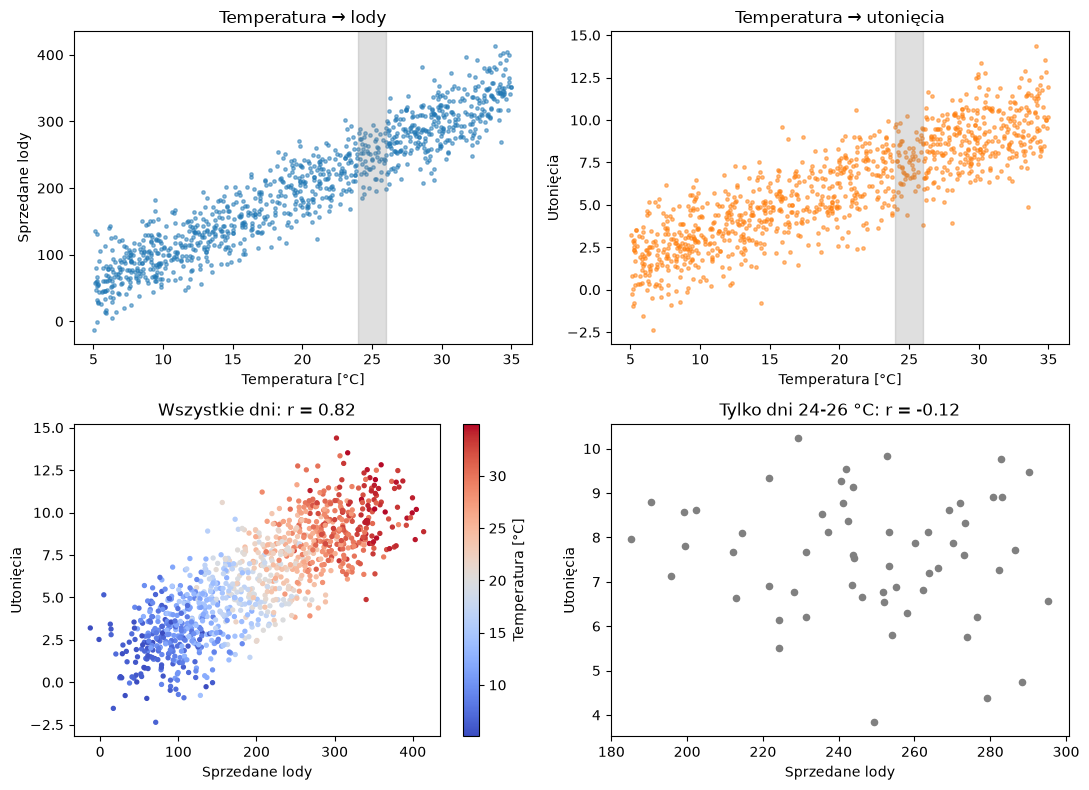

In [17]:
fig, osie = plt.subplots(2, 2, figsize=(11, 8))

# górne wykresy: temperatura wpływa na obie wielkości
osie[0, 0].scatter(temp, lody, s=6, alpha=0.5)
osie[0, 0].set_xlabel('Temperatura [°C]')
osie[0, 0].set_ylabel('Sprzedane lody')
osie[0, 0].set_title('Temperatura → lody')

osie[0, 1].scatter(temp, utoniecia, s=6, alpha=0.5, color='tab:orange')
osie[0, 1].set_xlabel('Temperatura [°C]')
osie[0, 1].set_ylabel('Utonięcia')
osie[0, 1].set_title('Temperatura → utonięcia')

for ax in osie[0]:
    ax.axvspan(24, 26, color='gray', alpha=0.25)  # dni o podobnej temperaturze

# dolny lewy: wszystkie dni, kolor = temperatura
sc = osie[1, 0].scatter(lody, utoniecia, c=temp, cmap='coolwarm', s=8)
osie[1, 0].set_title(f"Wszystkie dni: r = {np.corrcoef(lody, utoniecia)[0, 1]:.2f}")
osie[1, 0].set_xlabel('Sprzedane lody')
osie[1, 0].set_ylabel('Utonięcia')
fig.colorbar(sc, ax=osie[1, 0], label='Temperatura [°C]')

# dolny prawy: tylko dni o temperaturze 24-26 °C
osie[1, 1].scatter(lody[podobna_temp], utoniecia[podobna_temp], s=20, color='gray')
r_wąskie = np.corrcoef(lody[podobna_temp], utoniecia[podobna_temp])[0, 1]
osie[1, 1].set_title(f"Tylko dni 24-26 °C: r = {r_wąskie:.2f}")
osie[1, 1].set_xlabel('Sprzedane lody')
osie[1, 1].set_ylabel('Utonięcia')

plt.tight_layout()
plt.show()

Gdy „odetniemy” wpływ temperatury, korelacja praktycznie znika. **Model ML znajduje zależności, ale nie wyjaśnia przyczyn** – interpretację zawsze trzeba oprzeć na wiedzy o dziedzinie.

## 1.4 Próbka i populacja

W praktyce nigdy nie mamy wszystkich danych (całej *populacji*), tylko *próbkę*. Im większa próbka, tym lepiej jej statystyki przybliżają prawdę. Dlatego model oceniamy na osobnym zbiorze testowym, a nie na tych samych danych, na których się uczył.

**Skąd te dane?** `populacja` to 1 000 000 „osób” (wzrost z rozkładu normalnego 170 ± 10) – traktujemy ją jako *całą* populację, której prawdziwą średnią znamy. `rng.choice(populacja, size=n)` losuje z niej próbkę `n` osób (domyślnie ze zwracaniem, co przy milionie elementów nie ma znaczenia). Dla małych `n` średnia próbki mocno „skacze”, dla dużych jest bliska prawdziwej.

In [ ]:
populacja = rng.normal(170, 10, 1_000_000)
print(f"Prawdziwa średnia populacji: {populacja.mean():.2f}")
for n in (10, 100, 10_000):
    proba = rng.choice(populacja, size=n)
    print(f"próbka n={n:>6}: średnia = {proba.mean():.2f}")

## 1.5 Prawdopodobieństwo w pigułce

**Prawdopodobieństwo** zdarzenia to (w przybliżeniu) jego względna częstość. **Prawdopodobieństwo warunkowe** $P(A\mid B)$ to prawdopodobieństwo $A$ *przy założeniu, że zaszło* $B$.

Przykład z biznesu: 1000 klientów, zdarzenie A – klient odszedł, zdarzenie B – klient złożył reklamację.

**Jak wygenerowaliśmy te dane?** Symulujemy 1000 klientów w trzech krokach:
1. `reklamacja = rng.random(n) < 0.30` – `rng.random(n)` losuje liczby z przedziału $[0, 1)$; porównanie `< 0.30` daje `True` średnio dla 30% klientów (tablica wartości logicznych: klient złożył reklamację lub nie).
2. `szansa = np.where(reklamacja, 0.45, 0.10)` – każdemu klientowi przypisujemy jego własne prawdopodobieństwo odejścia: 45% po reklamacji, 10% bez reklamacji. W ten sposób *wbudowujemy* w dane zależność, którą zaraz odkryjemy.
3. `odszedl = rng.random(n) < szansa` – „rzut monetą” dla każdego klienta osobno: odchodzi, jeśli wylosowana liczba jest mniejsza od jego `szansa`.

Dalej: średnia z tablicy `True`/`False` to odsetek `True`, `odszedl[reklamacja]` wybiera tych, którzy złożyli reklamację, a `~reklamacja` to negacja maski. Z założeń wynika, że $P(\text{odejście}) = 0{,}3\cdot0{,}45+0{,}7\cdot0{,}10 = 0{,}205$ – wynik z symulacji powinien być bliski tej wartości.

In [ ]:
n = 1000
reklamacja = rng.random(n) < 0.30                   # 30% klientów składa reklamację
szansa = np.where(reklamacja, 0.45, 0.10)           # odchodzą częściej, gdy była reklamacja
odszedl = rng.random(n) < szansa

print(f"P(odejście)                  = {odszedl.mean():.2f}")
print(f"P(odejście | reklamacja)     = {odszedl[reklamacja].mean():.2f}")
print(f"P(odejście | brak reklamacji) = {odszedl[~reklamacja].mean():.2f}")

**Klasyfikator** robi dokładnie to samo: oblicza $P(\text{odejście} \mid \text{cechy klienta})$. Regresja logistyczna (Dzień 3) zwraca właśnie takie prawdopodobieństwo.

# 2. Algebra liniowa

Algebra liniowa to **język zapisu danych i modeli w ML**: obserwacje, cechy i wagi to wektory i macierze. Dzięki temu miliony obliczeń zapisujemy jednym wyrażeniem, a NumPy wykonuje je szybko (rozdział „Dlaczego NumPy?”).

## 2.1 Skalar, wektor, macierz, tensor

| Obiekt | Wymiary | W ML |
|---|---|---|
| skalar | 0 | pojedyncza liczba, np. wartość funkcji straty |
| wektor | 1 | jedna obserwacja (jej cechy) lub wagi modelu |
| macierz | 2 | cały zbiór danych: wiersze = obserwacje, kolumny = cechy |
| tensor | 3 i więcej | np. zbiór obrazów: (liczba obrazów, wysokość, szerokość) |

In [ ]:
X = np.array([[35, 5200, 2],
              [42, 7800, 1],
              [28, 4100, 3]])   # 3 klientów x 3 cechy: wiek, dochód, liczba produktów

obiekty = {
    'skalar': np.array(5),
    'wektor (1 klient)': X[0],
    'macierz (zbiór danych)': X,
    'tensor (100 obrazów 28x28)': np.zeros((100, 28, 28)),
}
for nazwa, t in obiekty.items():
    print(f"{nazwa:28} ndim={t.ndim}  shape={t.shape}")

Standardowa konwencja w ML: macierz danych $X$ ma kształt **(liczba obserwacji, liczba cech)**. Z taką konwencją spotkasz się w scikit-learn, Pandas i Keras.

## 2.2 Działania na wektorach

Wektory dodajemy i mnożymy przez liczbę **element po elemencie**. Geometrycznie: dodawanie to „przejście” najpierw wzdłuż jednego wektora, potem drugiego.

In [ ]:
a = np.array([2, 1])
b = np.array([1, 3])
print("a + b =", a + b)
print("3 * a =", 3 * a)

In [ ]:
wektory = [a, b, a + b]
plt.figure(figsize=(4.5, 4.5))
plt.quiver([0, 0, 0], [0, 0, 0], [v[0] for v in wektory], [v[1] for v in wektory],
           angles='xy', scale_units='xy', scale=1, color=['tab:blue', 'tab:orange', 'tab:green'])
for v, nazwa in zip(wektory, ['a', 'b', 'a + b']):
    plt.text(v[0] + 0.1, v[1] + 0.1, nazwa)
plt.xlim(-1, 5)
plt.ylim(-1, 5)
plt.gca().set_aspect('equal')
plt.grid(ls=':')
plt.title('Dodawanie wektorów')
plt.show()

## 2.3 Iloczyn skalarny

Iloczyn skalarny (*dot product*) to suma iloczynów odpowiadających sobie elementów:

$$\mathbf{a}\cdot\mathbf{b} = a_1 b_1 + a_2 b_2 + \dots + a_n b_n$$

In [ ]:
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])
np.dot(a, b), a @ b, (a * b).sum()  # trzy zapisy tego samego: 1*4 + 2*5 + 3*6

### Zastosowanie 1: suma ważona (neuron, regresja)

Wycena mieszkania: cechy $x$ (metraż, liczba pokoi, wiek budynku) mnożymy przez **wagi** $w$ i dodajemy wyraz wolny $b$:

$$\hat{y} = \mathbf{w}\cdot\mathbf{x} + b$$

To **cała regresja liniowa** (a także pojedynczy neuron sieci neuronowej).

In [ ]:
x = np.array([60, 3, 10])            # 60 m2, 3 pokoje, 10 lat
w = np.array([8000, 5000, -1000])    # zł za m2, zł za pokój, zł za każdy rok wieku
b = 50_000                           # wyraz wolny
cena = w @ x + b
cena

### Zastosowanie 2: podobieństwo (kosinus kąta)

Iloczyn skalarny mierzy też „zgodność kierunków” wektorów. **Podobieństwo kosinusowe** $\cos\theta = \dfrac{\mathbf{a}\cdot\mathbf{b}}{\|\mathbf{a}\|\,\|\mathbf{b}\|}$ (1 – ten sam kierunek, 0 – brak podobieństwa) jest podstawą porównywania tekstów. Tu: liczba wystąpień słów w trzech dokumentach.

In [ ]:
#                  python dane model futbol
dok1 = np.array([3, 2, 4, 0])   # artykuł o ML
dok2 = np.array([2, 3, 3, 0])   # inny artykuł o ML
dok3 = np.array([0, 0, 1, 5])   # artykuł sportowy

def kosinus(u, v):
    return u @ v / (np.linalg.norm(u) * np.linalg.norm(v))

print(f"dok1 vs dok2 (oba o ML)  : {kosinus(dok1, dok2):.2f}")
print(f"dok1 vs dok3 (ML i sport): {kosinus(dok1, dok3):.2f}")

## 2.4 Norma i odległość

**Norma** wektora to jego „długość”:
- norma L2 (euklidesowa): $\|\mathbf{v}\|_2 = \sqrt{v_1^2 + \dots + v_n^2}$,
- norma L1 (taksówkowa): $\|\mathbf{v}\|_1 = |v_1| + \dots + |v_n|$.

**Odległość** punktów $p$ i $q$ to norma ich różnicy: $d(p, q) = \|p - q\|_2$. Odległości są sercem kNN i klasteryzacji, a normy L1/L2 – regularyzacji.

In [ ]:
v = np.array([3, 4])
print("L2:", np.linalg.norm(v))        # 5 (trójkąt 3-4-5)
print("L1:", np.linalg.norm(v, 1))     # 3 + 4 = 7

In [ ]:
p = np.array([3, 0, 1])
q = np.array([0, 4, 2])
np.linalg.norm(p - q)  # odległość w przestrzeni 3D (tak samo działa dla setek cech)

### Dlaczego skalujemy cechy?

Klient A: 30 lat, dochód 5000 zł. Klient B: 45 lat, dochód 6500 zł. Ile każda cecha wnosi do odległości?

In [ ]:
A = np.array([30, 5000])
B = np.array([45, 6500])

print("Odległość surowa:", round(np.linalg.norm(A - B), 1))
print("Wkład cech [wiek, dochód] do kwadratu odległości:", (A - B) ** 2)

Różnica dochodu (1500) całkowicie „przykryła” różnicę wieku (15), choć 15 lat to duża różnica. Po podzieleniu przez typowe odchylenia (wiek ≈ 12 lat, dochód ≈ 1500 zł) cechy liczą się współmiernie:

In [ ]:
typowe_odchylenia = np.array([12, 1500])
roznica = (A - B) / typowe_odchylenia
print("Różnice po standaryzacji:", roznica)
print("Wkład cech do kwadratu odległości:", roznica ** 2)

**Wniosek:** algorytmy oparte na odległościach (kNN, klasteryzacja) i na gradientach (sieci neuronowe) wymagają cech w podobnych skalach. Wrócimy do tego na Dniu 2.

## 2.5 Mnożenie macierzy

Macierz $A$ o kształcie $m\times n$ można pomnożyć przez $B$ o kształcie $n\times p$. Wynik ma kształt $m\times p$, a element $c_{ij}$ to iloczyn skalarny $i$-tego wiersza $A$ i $j$-tej kolumny $B$.

W ML to najważniejsza operacja: **predykcje dla wszystkich obserwacji naraz** to jedno mnożenie macierzy danych przez wektor wag. Użyjmy mieszkań z poprzedniego przykładu (4 mieszkania, 3 cechy):

In [ ]:
X = np.array([[60, 3, 10],
              [45, 2, 25],
              [90, 4, 5],
              [30, 1, 40]])        # kształt (4, 3): metraż, pokoje, wiek budynku
w = np.array([8000, 5000, -1000])  # kształt (3,)
b = 50_000

X @ w + b  # kształt (4,): cena każdego mieszkania, bez pętli

In [ ]:
[wiersz @ w + b for wiersz in X]  # to samo, ale pętlą (wolniej, dłużej)

W sieci neuronowej warstwa liczy to samo dla wielu neuronów naraz: $X W + b$, gdzie $W$ ma kształt (liczba cech, liczba neuronów). Pomnóżmy dane przez macierz wag dla 2 neuronów:

**Skąd macierz wag?** `rng.normal(size=(3, 2))` losuje macierz $3\times 2$ z rozkładu normalnego (średnia 0, odchylenie 1). W prawdziwej sieci neuronowej wagi na starcie też są losowe, a potem są uczone. Tu interesuje nas tylko **kształt wyniku**.

In [ ]:
W = rng.normal(size=(3, 2))   # wagi: 3 cechy -> 2 neurony
(X @ W).shape                 # (4, 3) @ (3, 2) -> (4, 2)

Pamiętaj: mnożenie macierzy **nie jest przemienne** ($AB\neq BA$), a kształty muszą do siebie pasować. Gdy zobaczysz błąd `shapes not aligned`, sprawdź `.shape` obu macierzy.

## 2.6 Transpozycja

**Transpozycja** $A^T$ zamienia wiersze z kolumnami. Zmienia kształt $(m, n)$ na $(n, m)$. Przyda się za chwilę – w równaniu regresji liniowej pojawia się $X^T X$.

In [ ]:
print(X.shape, "->", X.T.shape)
print("X.T @ X ma kształt", (X.T @ X).shape, "(kwadratowa macierz: liczba cech x liczba cech)")

## 2.7 Macierz jednostkowa, odwrotna i wyznacznik

- **Macierz jednostkowa** $I$ ma jedynki na przekątnej i zera poza nią; jest „jedynką” macierzy: $AI = IA = A$.
- **Macierz odwrotna** $A^{-1}$ spełnia $AA^{-1} = I$ (odpowiednik odwrotności liczby, $5\cdot\frac15 = 1$).
- **Wyznacznik** $\det A$ to liczba, która mówi, czy macierz kwadratowa jest odwracalna: $\det A\neq 0$ – tak, $\det A = 0$ – nie (macierz **osobliwa**). Dla $2\times 2$: $\det A = a_{11}a_{22} - a_{12}a_{21}$.

In [ ]:
A = np.array([[2, 4],
              [-1, 3]])

print("det A =", round(np.linalg.det(A), 6))   # 2*3 - 4*(-1) = 10
A_inv = np.linalg.inv(A)
A_inv

In [ ]:
np.allclose(A @ A_inv, np.eye(2))  # A * A^-1 = I (z dokładnością do błędów zaokrągleń)

### Macierz osobliwa

Gdy jedna kolumna jest wielokrotnością innej (np. dwie cechy niosą tę samą informację, jak „cena w zł” i „cena w groszach”), wyznacznik wynosi 0 i macierzy nie da się odwrócić. W ML nazywamy to **współliniowością cech** i powoduje problemy w regresji liniowej.

In [ ]:
S = np.array([[1, 2],
              [2, 4]])   # druga kolumna = 2 * pierwsza
print("det S =", np.linalg.det(S))
try:
    np.linalg.inv(S)
except np.linalg.LinAlgError as e:
    print("Błąd:", e)

## 2.8 Układy równań i regresja liniowa

Układ równań
$$\begin{cases}2x + 4y = 10 \\ x - y = -1\end{cases}$$
zapisujemy jako $A\mathbf{u} = \mathbf{c}$, gdzie $A$ to macierz współczynników, a rozwiązaniem (dla odwracalnej $A$) jest $\mathbf{u} = A^{-1}\mathbf{c}$. W praktyce używamy `np.linalg.solve` – jest szybsze i dokładniejsze niż jawne odwracanie.

In [ ]:
A = np.array([[2, 4],
              [1, -1]])
c = np.array([10, -1])
np.linalg.solve(A, c)  # x = 1, y = 2

### Finał: regresja liniowa jednym równaniem

Mamy dane $(x, y)$ i szukamy prostej $y = w_0 + w_1 x$. Dodajemy do $X$ kolumnę jedynek (to wyraz wolny $w_0$). Wagi, które najlepiej dopasowują prostą (w sensie najmniejszych kwadratów), spełniają **równanie normalne**:

$$X^T X\,\mathbf{w} = X^T \mathbf{y}$$

To zwykły układ równań – rozwiązujemy go dokładnie tak, jak powyżej. Wygenerujemy dane z prostej $y = 3 + 2x$ z szumem i sprawdzimy, czy odzyskamy współczynniki 3 i 2:

**Jak wygenerowaliśmy te dane?** `x = rng.uniform(0, 10, 100)` to 100 losowych punktów z przedziału 0–10. Wartości `y` liczymy z **prawdziwej prostej** $y = 3 + 2x$ i dodajemy szum `rng.normal(0, 0.5, 100)` – losowe błędy pomiaru o odchyleniu 0,5. Dzięki temu znamy „prawdziwe” współczynniki (3 i 2) i możemy sprawdzić, czy metoda je odzyska, mimo szumu.

In [ ]:
x = rng.uniform(0, 10, 100)
y = 3 + 2 * x + rng.normal(0, 0.5, 100)           # prawdziwa prosta + szum

X = np.column_stack([np.ones_like(x), x])      # kolumna jedynek + cecha, kształt (100, 2)
w = np.linalg.solve(X.T @ X, X.T @ y)
print(f"Odzyskane wagi: w0 = {w[0]:.2f}, w1 = {w[1]:.2f}  (prawdziwe: 3 i 2)")

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(x, y, s=12, label='dane')
plt.plot(x, X @ w, color='red', label='dopasowana prosta')  # predykcje = jedno mnożenie macierzy
plt.legend()
plt.grid(ls=':')
plt.show()

Użyliśmy tylko: transpozycji, mnożenia macierzy i rozwiązywania układu równań. **Na Dniu 3** zrobimy to krok po kroku, dodamy metryki jakości i drugą metodę uczenia – spadek wzdłuż gradientu.

# Podsumowanie

| Pojęcie | Zapamiętaj |
|---|---|
| Średnia i mediana | wartości odstające zmieniają średnią, mediana jest odporna |
| Rozkład normalny | 68–95–99,7% w ±1σ, ±2σ, ±3σ; standaryzacja: $z=(x-\mu)/\sigma$ |
| Korelacja | mierzy zależność liniową; nie dowodzi przyczynowości |
| Prawdopodobieństwo warunkowe | klasyfikator szacuje $P(\text{klasa}\mid\text{cechy})$ |
| Wektor, macierz | obserwacja = wektor, zbiór danych = macierz (obserwacje x cechy) |
| Iloczyn skalarny | suma ważona (neuron, regresja) i podobieństwo |
| Norma, odległość | podstawa kNN; dlatego skalujemy cechy |
| Mnożenie macierzy | predykcje dla całego zbioru naraz: $X\mathbf{w}$ |
| Równanie normalne | regresja liniowa = rozwiązanie układu $X^TX\mathbf{w}=X^T\mathbf{y}$ |
